# Reproduction notebook

Recomputes headline results from the code and compares each with a committed output
(`results/summary.json`, `results/data/`, `manas_sa/results/`). Expected values are always read from
those files, never typed in, and nothing is written under `results/`. The last cell fails if any check fails.

Runs in about a minute from the repository root or from `notebooks/`.
For a non-interactive version, run `python scripts/reproduce.py --ibm`.

In [1]:
import json, os, pathlib, sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = pathlib.Path.cwd()
if not (ROOT / "sexconflict").exists():            # started from notebooks/
    ROOT = ROOT.parent
sys.path[:0] = [str(ROOT), str(ROOT / "manas_sa")]
os.environ["SC_PROFILE"] = "full"                  # the committed results are the full profile

from sexconflict import config as C
from sexconflict.deterministic import owen_parsons as op
from sexconflict.deterministic import poster_model as pm
from sexconflict.ibm import runners as R
from iasc import estimators as Es

%config InlineBackend.figure_format = "png"
plt.rcParams["figure.dpi"] = 90

S = json.loads((ROOT / "results" / "summary.json").read_text(encoding="utf-8"))
checks = {}                                        # name -> passed?
env = S["environment"]
print(f"stored run: {env['timestamp']}, profile {env['profile']}, Python {env['python']}, numpy {env['numpy']}")

stored run: 2026-10-05 17:27:01, profile full, Python 3.14.6, numpy 2.5.3


## 1. Poster model: the IaSC polymorphism (P0)

The poster's formula p\* = ½ + ½(1/b − 1/a) against 20,000 iterations of the one-locus recursion,
exactly as in `sexconflict/experiments/poster_exp.py`.

In [2]:
P = C.POSTER
b = P.b_strong
lo, hi = pm.polymorphism_range(b)
a_fine = np.linspace(lo - 0.01, hi + 0.01, 400)
p = np.full_like(a_fine, 0.5)
for _ in range(20000):
    p = pm.one_locus_step(p, a_fine, b)
inner = (a_fine > lo + 1e-3) & (a_fine < hi - 1e-3)
dev = np.abs(p - np.clip(pm.pstar(a_fine, b), 0, 1))[inner].max()
stored = S["poster"]["P0 one-locus polymorphism"]["iterate_vs_formula"]
checks["P0: iterated recursion vs p*"] = bool(np.isclose(dev, stored, rtol=1e-6, atol=0))
print(f"max |iterated - p*| = {dev:.6e}   (stored run: {stored:.6e})")

max |iterated - p*| = 6.889755e-06   (stored run: 6.889755e-06)


## 2. Poster heatmap (P1, b = 0.2), recomputed from scratch

Fraction of the (a, r) rectangle in which the IaSC fixed point is stable (a rare modifier M1 cannot invade),
on the stored run's grids: 51 × 51 modifier effects (k1, k2), each over 101 × 101 values of (a, r).
Compared cell by cell with `results/data/P1_b0.2.npz`.

grid (51, 51); max |recomputed - stored| = 0.0


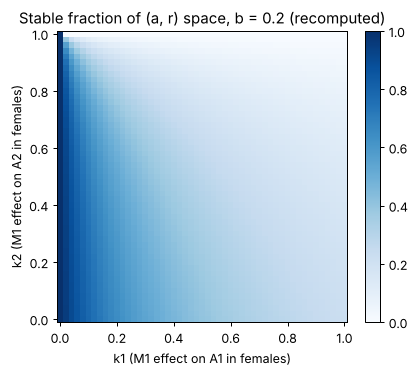

In [3]:
k = np.linspace(0, 1, P.heat_n)
K1, K2 = np.meshgrid(k, k)
F = pm.stable_fraction(b, K1, K2, n_a=P.ar_n, n_r=P.ar_n)
ref = np.load(ROOT / "results" / "data" / "P1_b0.2.npz")["frac"]
checks["P1: heatmap b = 0.2 identical to stored array"] = bool(np.array_equal(F, ref))
print(f"grid {F.shape}; max |recomputed - stored| = {np.abs(F - ref).max()}")

fig, ax = plt.subplots(figsize=(5.2, 4.2))
im = ax.pcolormesh(k, k, F, shading="nearest", vmin=0, vmax=1, cmap="Blues")
ax.set(xlabel="k1 (M1 effect on A1 in females)", ylabel="k2 (M1 effect on A2 in females)",
       title="Stable fraction of (a, r) space, b = 0.2 (recomputed)")
fig.colorbar(im, ax=ax)
plt.show()

## 3. Owen-type bistability (O4)

Interior equilibria of the autosomal sex-differential viability model for the stored bistable parameter set,
found numerically (no closed form assumed), with their stability. Compared with the stored run and with the
cubic quoted in the earlier AI blueprint (`Simulating Population Genetics Models.txt`).

p1 = 0.087125  p2 = 0.042616  stable = True    (stored: 0.087125, 0.042616, True)
p1 = 0.388114  p2 = 0.367007  stable = False   (stored: 0.388114, 0.367007, False)
p1 = 0.766115  p2 = 0.884838  stable = True    (stored: 0.766115, 0.884838, True)


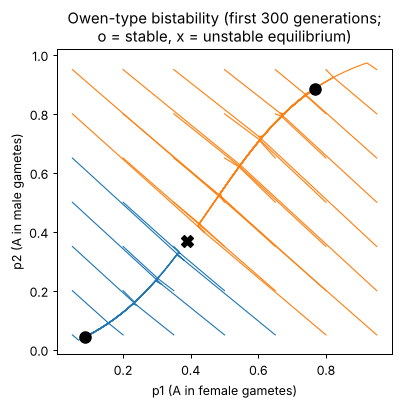

In [4]:
par = C.OWEN.bistable
eq = op.autosomal_equilibria(*par)
stored_eq = S["owen"]["O4 Owen bistability"]["equilibria"]
for e, s in zip(eq, stored_eq):
    print(f"p1 = {e['p1']:.6f}  p2 = {e['p2']:.6f}  stable = {str(e['stable']):5}"
          f"   (stored: {s['p1']:.6f}, {s['p2']:.6f}, {s['stable']})")
checks["O4: equilibria and stability vs stored"] = len(eq) == len(stored_eq) and all(
    np.isclose(e["p1"], s["p1"], rtol=1e-9) and np.isclose(e["p2"], s["p2"], rtol=1e-9)
    and e["stable"] == s["stable"] for e, s in zip(eq, stored_eq))
cubic = sorted(round(float(t[0]), 6) for t in op.blueprint_cubic_equilibria(*par))
checks["O4: blueprint cubic gives the same equilibria"] = cubic == sorted(round(float(e["p1"]), 6) for e in eq)

# oracle trajectories from a 7 x 7 grid of starts, coloured by the stable equilibrium
# each is nearest after 3,000 generations (the horizon used by the O4 experiment)
starts = np.linspace(0.05, 0.95, 7)
S1, S2 = np.meshgrid(starts, starts)
traj = op.iterate(op.autosomal_step, S1, S2, par, n_gen=3000, record=True)   # (generation, sex, i, j)
stable = [e for e in eq if e["stable"]]
fig, ax = plt.subplots(figsize=(4.8, 4.4))
for i in range(7):
    for j in range(7):
        end = traj[-1, :, i, j]
        near = int(np.argmin([np.hypot(end[0] - e["p1"], end[1] - e["p2"]) for e in stable]))
        ax.plot(traj[:300, 0, i, j], traj[:300, 1, i, j], color=("tab:blue", "tab:orange")[near], lw=0.9)
for e in eq:
    ax.plot(e["p1"], e["p2"], "o" if e["stable"] else "X", ms=9, color="k")
ax.set(xlabel="p1 (A in female gametes)", ylabel="p2 (A in male gametes)",
       title="Owen-type bistability (first 300 generations;\no = stable, x = unstable equilibrium)")
plt.show()

## 4. Individual-based model: P0 at N = 500, stored seeds

The zero-leakage IBM receives only the viability table, N and the founders; it never sees p\*.
Same settings and seeds as the stored run. Informational, not pass/fail: the stored run does not record
which backend (numba CPU or OpenCL GPU) produced this suite, and the two are statistically, not bit-for-bit,
equivalent.

RMSE of the IBM time-averaged A1 frequency vs p*: 0.124800456929  (stored run: 0.124800456929; identical)


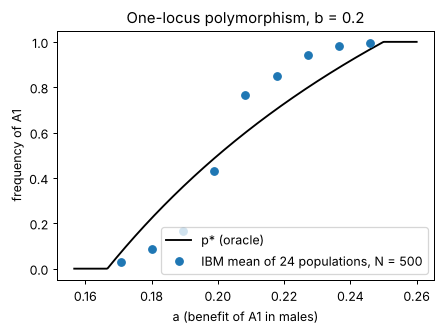

In [5]:
N = 500
a_ibm = np.linspace(lo + 0.004, hi - 0.004, 9)
means = []
for a in a_ibm:
    w = C.validate_viability(C.poster_viability(a, b, 0, 1))
    out = R.run_haploid([0, N // 2, 0, N - N // 2], w, 0.5, 1500, P.one_locus_reps,
                        C.seed_for("poster/" + f"ol{N}{a:.4f}"))
    means.append(out["pA1"][:, 500:].mean(1).mean())
means = np.array(means)
rmse = float(np.sqrt(np.mean((means - pm.pstar(a_ibm, b)) ** 2)))
stored = S["poster"]["P0 one-locus polymorphism"]["rmse_by_N"]["500"]
print(f"RMSE of the IBM time-averaged A1 frequency vs p*: {rmse:.12g}  (stored run: {stored:.12g}; "
      f"{'identical' if abs(rmse - stored) < 1e-12 else 'differs'})")

fig, ax = plt.subplots(figsize=(5.4, 3.6))
ax.plot(a_fine, np.clip(pm.pstar(a_fine, b), 0, 1), color="k", label="p* (oracle)")
ax.plot(a_ibm, means, "o", label=f"IBM mean of {P.one_locus_reps} populations, N = {N}")
ax.set(xlabel="a (benefit of A1 in males)", ylabel="frequency of A1", title="One-locus polymorphism, b = 0.2")
ax.legend()
plt.show()

## 5. Project 2, target 1: published statistics recomputed from the raw data

The estimators of Geeta Arun *et al.* (2022) (`manas_sa/iasc/estimators.py`) applied to the authors' supplementary
data (`experimental_papers_manas/12862_2022_1992_MOESM3_ESM.xlsx`, CC BY 4.0). Compared with the committed
`manas_sa/results/bmc2022_recomputed.csv` and with the published 4-decimal values stored in that file.

In [6]:
raw = pd.read_excel(ROOT / "experimental_papers_manas" / "12862_2022_1992_MOESM3_ESM.xlsx", header=1)
raw.columns = ["Sex", "SexRatio", "Day", "Line", "Fitness"]
raw = raw.dropna(subset=["Fitness"])
raw["Fitness"] = raw.Fitness.astype(float)
st = Es.paper_stats(Es.line_means(raw))

t = pd.read_csv(ROOT / "manas_sa" / "results" / "bmc2022_recomputed.csv").dropna(subset=["reported"])
t = t[t.statistic.isin(["r_wgmf", "prop_SA", "r_female_across", "r_male_across"])].copy()
t["now"] = [st[(s, l)] for s, l in zip(t.statistic, t.level)]
t["|now - committed|"] = (t.now - t.recomputed).abs()
t["|now - published|"] = (t.now - t.reported).abs()
checks["target 1: 12 statistics identical to committed CSV"] = bool(len(t) == 12 and t["|now - committed|"].max() < 1e-12)
checks["target 1: within 1e-4 of the published values"] = bool(t["|now - published|"].max() < 1e-4)
t[["statistic", "level", "now", "recomputed", "reported", "|now - committed|", "|now - published|"]].round(6)

,statistic,level,now,recomputed,reported,|now - committed|,|now - published|
0,r_wgmf,M,0.380548,0.380548,0.3805,0.0,0.000048
1,prop_SA,M,0.309726,0.309726,0.3097,0.0,0.000026
2,r_wgmf,E,0.402733,0.402733,0.4027,0.0,0.000033
3,prop_SA,E,0.298634,0.298634,0.2986,0.0,0.000034
4,r_wgmf,F,0.251515,0.251515,0.2515,0.0,0.000015
5,prop_SA,F,0.374243,0.374243,0.3742,0.0,0.000043
6,r_female_across,M-F,0.768836,0.768836,0.7688,0.0,0.000036
7,r_female_across,M-E,0.749311,0.749311,0.7493,0.0,0.000011
8,r_female_across,F-E,0.842173,0.842173,0.8421,0.0,0.000073
9,r_male_across,M-F,0.556724,0.556724,0.5567,0.0,0.000024


## Summary

In [7]:
width = max(map(len, checks))
for name, ok in checks.items():
    print(f"{name:<{width}}  {'PASS' if ok else 'FAIL'}")
assert all(checks.values()), "some checks failed"
print(f"\n{len(checks)}/{len(checks)} checks passed")

P0: iterated recursion vs p*                        PASS
P1: heatmap b = 0.2 identical to stored array       PASS
O4: equilibria and stability vs stored              PASS
O4: blueprint cubic gives the same equilibria       PASS
target 1: 12 statistics identical to committed CSV  PASS
target 1: within 1e-4 of the published values       PASS

6/6 checks passed
